#### Task 3 (Extra Stuff to Link to Networks)
To further explore if the different road configuration using IDM would cause congestion and at what density
1. Multiple Rings
2. Freeway
3. Oval with long stretches of straight Road

#### Question: 
Does different road configuration affect the density required?
Yes, the free highway can contain vehicles with the highest densities

In [58]:
# Some libraries used
import tomllib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Different Ring Road Geometry

In [59]:
ROOT = Path.cwd().resolve().parent

df = pd.read_csv(ROOT / "results" / "different_track" / "idm_geometry_comparison.csv")
df.head(10)

df = df[(df["status"] == "ok") & (df["seed"].between(501, 503))].copy()
df = df.drop_duplicates(subset="run_id", keep="last")
df["defined_density_veh_km"] = (df["vehicles_requested"] / (df["length_m"] / 1000))

df.head(10)

,config,run_id,network_type,length_m,lanes,vehicles_requested,seed,initial_target_density_veh_km_total,initial_target_density_veh_km_lane,inflow_requested_veh_h_lane,...,speed_std_mps,jam_fraction_vehicle_samples,estimated_flow_veh_h_total,vehicles_seen_unique,first_sample_vehicles,last_sample_vehicles,status,error,run_dir,defined_density_veh_km
0,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n48_s501,oval,4800.0,1,48,501,10.0,10.0,0.0,...,0.000494,0.0,1015.560881,48,48,48,ok,NaN,runs/oval_idm_L4800_m1_n48_s501,10.0
1,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n48_s502,oval,4800.0,1,48,502,10.0,10.0,0.0,...,0.000000,0.0,1015.560000,48,48,48,ok,NaN,runs/oval_idm_L4800_m1_n48_s502,10.0
2,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n48_s503,oval,4800.0,1,48,503,10.0,10.0,0.0,...,0.000000,0.0,1015.560000,48,48,48,ok,NaN,runs/oval_idm_L4800_m1_n48_s503,10.0
3,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n72_s501,oval,4800.0,1,72,501,15.0,15.0,0.0,...,0.000004,0.0,1401.300000,72,72,72,ok,NaN,runs/oval_idm_L4800_m1_n72_s501,15.0
4,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n72_s502,oval,4800.0,1,72,502,15.0,15.0,0.0,...,0.000004,0.0,1401.300000,72,72,72,ok,NaN,runs/oval_idm_L4800_m1_n72_s502,15.0
5,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n72_s503,oval,4800.0,1,72,503,15.0,15.0,0.0,...,0.000004,0.0,1401.300000,72,72,72,ok,NaN,runs/oval_idm_L4800_m1_n72_s503,15.0
6,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n96_s501,oval,4800.0,1,96,501,20.0,20.0,0.0,...,0.000000,0.0,1653.840000,96,96,96,ok,NaN,runs/oval_idm_L4800_m1_n96_s501,20.0
7,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n96_s502,oval,4800.0,1,96,502,20.0,20.0,0.0,...,0.000000,0.0,1653.840000,96,96,96,ok,NaN,runs/oval_idm_L4800_m1_n96_s502,20.0
8,configs/ring/idm_oval_freeway_4800.toml,oval_idm_L4800_m1_n96_s503,oval,4800.0,1,96,503,20.0,20.0,0.0,...,0.000000,0.0,1653.840000,96,96,96,ok,NaN,runs/oval_idm_L4800_m1_n96_s503,20.0
27,configs/ring/idm_open_freeway_4800.toml,freeway_idm_L4800_m1_n48_s501,freeway,4800.0,1,48,501,10.0,10.0,1200.0,...,0.352755,0.0,1199.702500,458,58,58,ok,NaN,runs/freeway_idm_L4800_m1_n48_s501,10.0


In [60]:
speed_summary = (df.groupby(["network_type", "defined_density_veh_km"]).agg(mean_speed_mps=("mean_speed_mps", "mean"), std_speed_mps=("mean_speed_mps", "std"), n_seeds=("seed", "nunique"))
    .reset_index()
    .sort_values(
        ["network_type", "defined_density_veh_km"]
    )
)


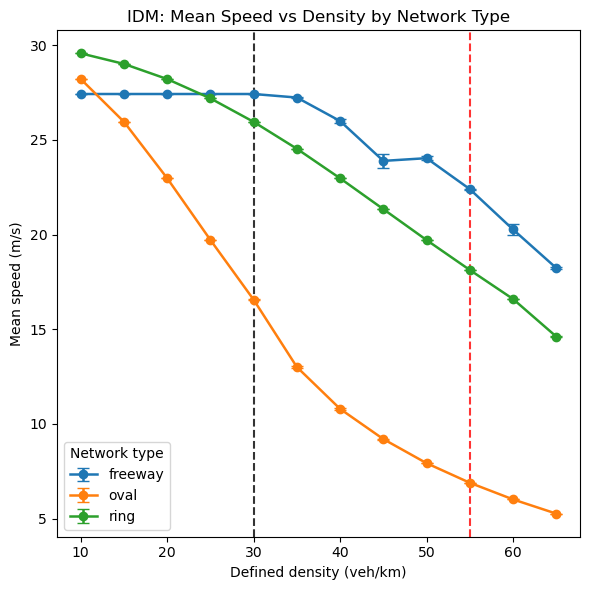

In [71]:
# To visualize the plots for the different type of network
fig, ax = plt.subplots(figsize=(6, 6))

for network_type, group in speed_summary.groupby("network_type"):

    ax.errorbar(group["defined_density_veh_km"], group["mean_speed_mps"], yerr=group["std_speed_mps"].fillna(0), marker="o", capsize=4, linewidth=1.8, label=network_type)

ax.axvline(x=30, color="black", linestyle="--", linewidth=1.5, alpha=0.8)
ax.axvline(x=55, color="red", linestyle="--", linewidth=1.5, alpha=0.8)

ax.set_xlabel("Defined density (veh/km)")
ax.set_ylabel("Mean speed (m/s)")
ax.set_title("IDM: Mean Speed vs Density by Network Type")

ax.legend(title="Network type")

plt.tight_layout()
plt.show()


Then to see the jamed fraction to see if it correspondds to the speed. 

In [62]:
# Aggregate jam fraction across seeds
jam_summary = (df.groupby(["network_type", "defined_density_veh_km"])
    .agg(mean_jam_fraction=("jam_fraction_vehicle_samples", "mean"),
        std_jam_fraction=("jam_fraction_vehicle_samples", "std"),
        n_seeds=("seed", "nunique")).reset_index().sort_values(
        ["network_type", "defined_density_veh_km"]
    )
)

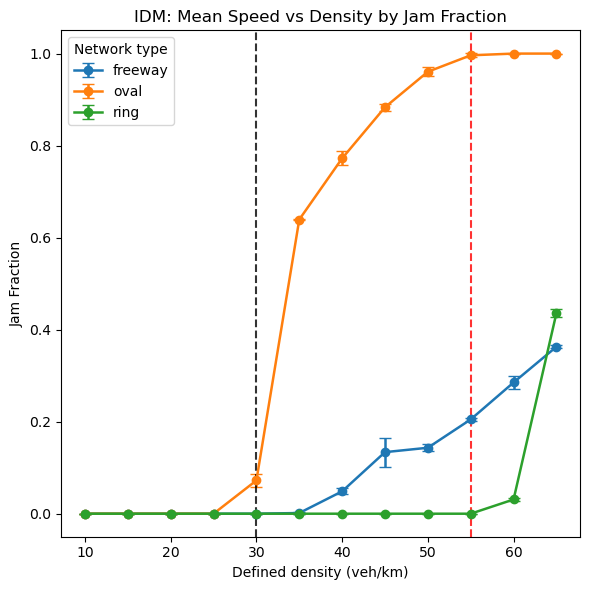

In [72]:
fig, ax = plt.subplots(figsize=(6, 6))

for network_type, group in jam_summary.groupby("network_type"):

    ax.errorbar(group["defined_density_veh_km"], group["mean_jam_fraction"], yerr=group["std_jam_fraction"].fillna(0), marker="o", capsize=4, linewidth=1.8, label=network_type)

ax.axvline(x=30, color="black", linestyle="--", linewidth=1.5, alpha=0.8)
ax.axvline(x=55, color="red", linestyle="--", linewidth=1.5, alpha=0.8)

ax.set_xlabel("Defined density (veh/km)")
ax.set_ylabel("Jam Fraction")
ax.set_title("IDM: Mean Speed vs Density by Jam Fraction")

ax.legend(title="Network type")

plt.tight_layout()
plt.show()

Then to calculate the flow
Flow = Density * Mean Speed

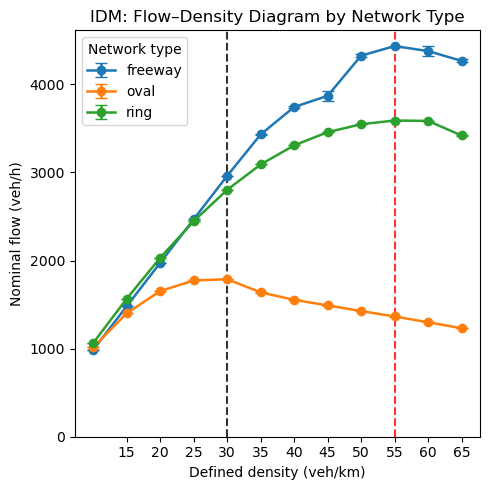

In [73]:
# Fundamental Diagram

df["flow_veh_h"] = (df["defined_density_veh_km"]* df["mean_speed_mps"]* 3.6)
flow_summary = (df.groupby(["network_type", "defined_density_veh_km"]).agg(mean_flow_veh_h=("flow_veh_h", "mean"), std_flow_veh_h=("flow_veh_h", "std"), n_seeds=("seed", "nunique")).reset_index().sort_values(["network_type", "defined_density_veh_km"]))

fig, ax = plt.subplots(figsize=(5, 5))

for network_type, group in flow_summary.groupby("network_type"):

    ax.errorbar(
        group["defined_density_veh_km"],
        group["mean_flow_veh_h"],
        yerr=group["std_flow_veh_h"].fillna(0),
        marker="o",
        linewidth=1.8,
        capsize=4,
        label=network_type
    )

ax.axvline(x=30, color="black", linestyle="--", linewidth=1.5, alpha=0.8)
ax.axvline(x=55, color="red", linestyle="--", linewidth=1.5, alpha=0.8)

ax.set_xlabel("Defined density (veh/km)")
ax.set_ylabel("Nominal flow (veh/h)")
ax.set_title("IDM: Flow–Density Diagram by Network Type")
ax.set_xticks([15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65])
ax.set_ylim(bottom=0)
ax.legend(title="Network type")

plt.tight_layout()
plt.show()

To plot some space time diagram
1. Taken help from ChatGPT

In [65]:
import xml.etree.ElementTree as ET

ROOT = Path.cwd().resolve().parent

N = 288
SEED = 501
LENGTH = 4800

networks = {
    "Closed Oval": {"run_id": f"oval_idm_L4800_m1_n{N}_s{SEED}", "net_file": "oval_4800_lanes1.net.xml",},
    "Open Freeway": {"run_id": f"freeway_idm_L4800_m1_n{N}_s{SEED}", "net_file": "freeway_4800_lanes1.net.xml",},
    "Multi-lane Ring": {"run_id": f"ring_idm_L4800_m2_n{N}_s{SEED}", "net_file": "ring_4800_lanes2.net.xml",}}


In [66]:
def read_network_offsets(net_path):
    root = ET.parse(net_path).getroot()

    edge_lengths = {}

    for edge in root.findall("edge"):
        edge_id = edge.get("id", "")

        if edge_id.startswith("e") and edge_id[1:].isdigit():
            lane = edge.find("lane")

            if lane is not None:
                edge_lengths[edge_id] = float(
                    lane.get("length")
                )

    edge_order = sorted(
        edge_lengths,
        key=lambda e: int(e[1:])
    )

    offsets = {}
    total_length = 0.0

    for edge_id in edge_order:
        offsets[edge_id] = total_length
        total_length += edge_lengths[edge_id]

    return offsets, total_length


In [67]:
# GPT function to generate the plot
def make_speed_heatmap(fcd_path,net_path,dx=50,dt=10,t_max=1800,lane_filter=None,):
    
    offsets, length = read_network_offsets(net_path)
    n_x = int(np.ceil(length / dx))
    n_t = int(np.ceil(t_max / dt))

    speed_sum = np.zeros((n_x, n_t))
    speed_count = np.zeros((n_x, n_t))

    current_time = None

    for event, elem in ET.iterparse(
        fcd_path, events=("start", "end")
    ):
        if event == "start" and elem.tag == "timestep":
            current_time = float(elem.get("time"))

        elif event == "end" and elem.tag == "vehicle":
            lane_id = elem.get("lane", "")

            if lane_filter is not None:
                if not lane_id.endswith(f"_{lane_filter}"):
                    elem.clear()
                    continue

            edge_id = lane_id.rsplit("_", 1)[0]

            if edge_id in offsets and current_time is not None:
                x = offsets[edge_id] + float(
                    elem.get("pos", 0)
                )
                v = float(elem.get("speed", 0))

                x_bin = int(x // dx)
                t_bin = int(current_time // dt)

                if 0 <= x_bin < n_x and 0 <= t_bin < n_t:
                    speed_sum[x_bin, t_bin] += v
                    speed_count[x_bin, t_bin] += 1

            elem.clear()

    mean_speed = np.divide(speed_sum, speed_count, out=np.full_like(speed_sum, np.nan), where=speed_count > 0,)

    return mean_speed, length


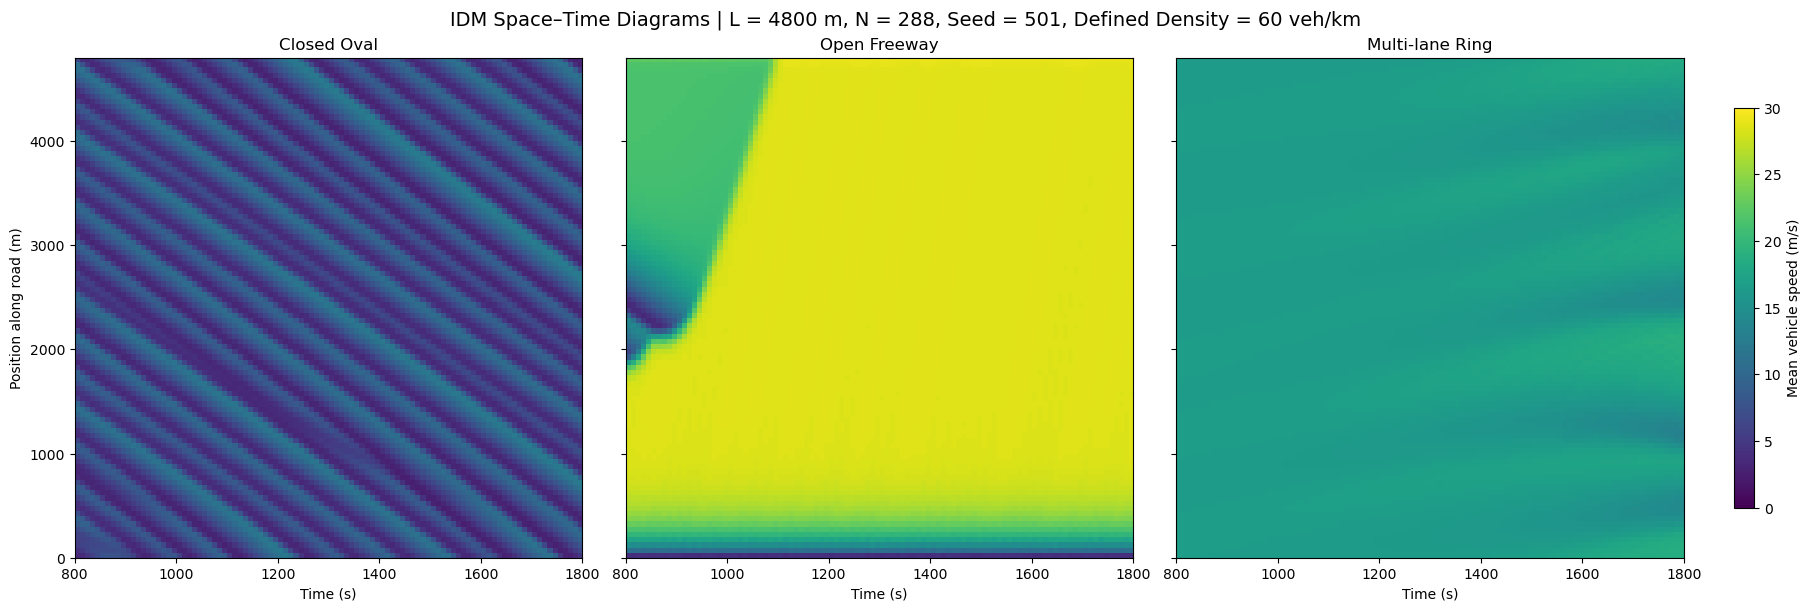

In [68]:
dx = 50
dt = 10
t_max = 1800

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True, constrained_layout=True)

image = None

for ax, (network_name, cfg) in zip(axes, networks.items()):
    fcd_path = (ROOT / "runs" / cfg["run_id"] / "fcd.xml")
    net_path = (ROOT / "scenarios" / "ring" / cfg["net_file"])

    if not fcd_path.exists() or not net_path.exists():
        ax.set_title(f"{network_name}\nMissing files")
        print(f"Missing: {fcd_path} or {net_path}")
        continue

    speed_grid, road_length = make_speed_heatmap(fcd_path=fcd_path, net_path=net_path, dx=dx, dt=dt, t_max=t_max)

    image = ax.imshow(speed_grid, origin="lower", aspect="auto",
        extent=[0, t_max, 0, road_length], cmap="viridis", vmin=0, vmax=30, interpolation="nearest")

    ax.set_title(network_name)
    ax.set_xlabel("Time (s)")
    ax.grid(False)
    ax.set_xlim(800, 1800)

axes[0].set_ylabel("Position along road (m)")

if image is not None:
    cbar = fig.colorbar(image, ax=axes, shrink=0.8, pad=0.02)
    cbar.set_label("Mean vehicle speed (m/s)")

fig.suptitle(
    f"IDM Space–Time Diagrams | "
    f"L = {LENGTH} m, N = {N}, "
    f"Seed = {SEED}, Defined Density = {N / 4.8:g} veh/km",
    fontsize=14
)

plt.show()

Open free way where the traffice progressively disappers and then by the faster flows. The two-lane ring shows no clear strong stop and go. 

### Final Interpretation:

The closed oval develops persistent backward-moving congestion bands.

The open freeway’s initial congestion clears downstream.

The two-lane ring remains considerably more stable because the same vehicles are distributed across two lanes.

The space–time plotting code correctly converts each edge position into a continuous network coordinate.

Other Consideration (?):
